# Emergency Room (ER) Daily Patient Admissions Forecasting
**Course:** Predictive Analytics (CSE3141) — Mini Project
**Name:** Kashish Gupta  **Reg. No.:** 2427030366  **Section:** A

### Problem statement
Hospital administrators must decide how many doctors and nurses to roster each day. Too few staff → long waits and unsafe care; too many → wasted cost.
This project builds a model that predicts the **number of ER admissions per day (Y)** from:

| Feature (X) | Type | Example |
|---|---|---|
| `weather_alert` | Categorical | No Alert / Heatwave / Coldwave |
| `day_of_week` | Categorical | Monday … Sunday |
| `aqi` | Numeric | Air Quality Index, 0–500 |
| `flu_season` | Binary | Yes / No |

and then converts the forecast into a **staffing recommendation** that accounts for surges under poor environmental conditions.

### Approach
1. Clean & explore the data (EDA)
2. Train three models: **Multiple Linear Regression** (baseline), **Negative Binomial Regression** (count model), **Random Forest** (non-linear ML)
3. Evaluate on unseen data (year 2025) using MAE, RMSE, R², MAPE
4. Interpret each factor as a **% surge** in patients
5. Build a staffing calculator for “what-if” scenarios

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy.stats import nbinom
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)
DAY_ORDER = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

## 1. Load and inspect the data
The dataset has one row per day for 3 years (2023–2025). It is synthetic, built by `generate_data.py` to mimic Delhi’s climate patterns, because real patient-level hospital records are confidential.

In [2]:
df = pd.read_csv("data/er_admissions.csv", parse_dates=["date"])
print(df.shape)
df.head()

(1096, 6)


,date,day_of_week,weather_alert,aqi,flu_season,er_admissions
0,2023-01-01,Sunday,Coldwave,350.0,Yes,175
1,2023-01-02,Monday,No Alert,288.0,Yes,212
2,2023-01-03,Tuesday,No Alert,368.0,Yes,113
3,2023-01-04,Wednesday,No Alert,NaN,Yes,123
4,2023-01-05,Thursday,No Alert,244.0,Yes,124


In [3]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1096 entries, 0 to 1095
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           1096 non-null   datetime64[us]
 1   day_of_week    1096 non-null   str           
 2   weather_alert  1096 non-null   str           
 3   aqi            1078 non-null   float64       
 4   flu_season     1096 non-null   str           
 5   er_admissions  1096 non-null   int64         
dtypes: datetime64[us](1), float64(1), int64(1), str(3)
memory usage: 51.5 KB


,date,aqi,er_admissions
count,1096,1078.000000,1096.000000
mean,2024-07-01 12:00:00,210.523191,137.118613
min,2023-01-01 00:00:00,35.000000,62.000000
25%,2023-10-01 18:00:00,114.000000,117.000000
50%,2024-07-01 12:00:00,210.500000,135.000000
75%,2025-04-01 06:00:00,302.000000,155.250000
max,2025-12-31 00:00:00,475.000000,243.000000
std,NaN,108.043661,29.348365


## 2. Data cleaning
Check for missing values (AQI sensors sometimes go offline).

In [4]:
print(df.isna().sum())

date              0
day_of_week       0
weather_alert     0
aqi              18
flu_season        0
er_admissions     0
dtype: int64


AQI changes smoothly from day to day, so we fill gaps with **linear interpolation** (the average of the neighbouring days) rather than dropping rows.

In [5]:
df["aqi"] = df["aqi"].interpolate(method="linear").round()
df["flu_season"] = (df["flu_season"] == "Yes").astype(int)     # Yes/No -> 1/0
df["day_of_week"] = pd.Categorical(df["day_of_week"], categories=DAY_ORDER)
df["weather_alert"] = pd.Categorical(df["weather_alert"], categories=["No Alert","Heatwave","Coldwave"])
print("Missing values left:", df.isna().sum().sum())

Missing values left: 0


## 3. Exploratory Data Analysis (EDA)

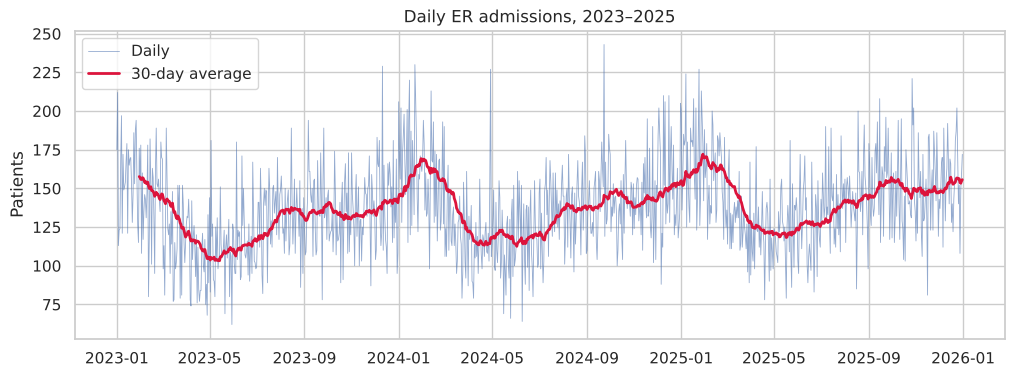

In [6]:
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(df["date"], df["er_admissions"], lw=0.6, alpha=0.6, label="Daily")
ax.plot(df["date"], df["er_admissions"].rolling(30).mean(), lw=2, color="crimson", label="30-day average")
ax.set_title("Daily ER admissions, 2023–2025"); ax.set_ylabel("Patients"); ax.legend()
plt.show()

**Observation:** Clear yearly peaks in winter (Dec–Jan: cold + worst air + flu) and a smaller one in monsoon (flu), plus slow upward growth.

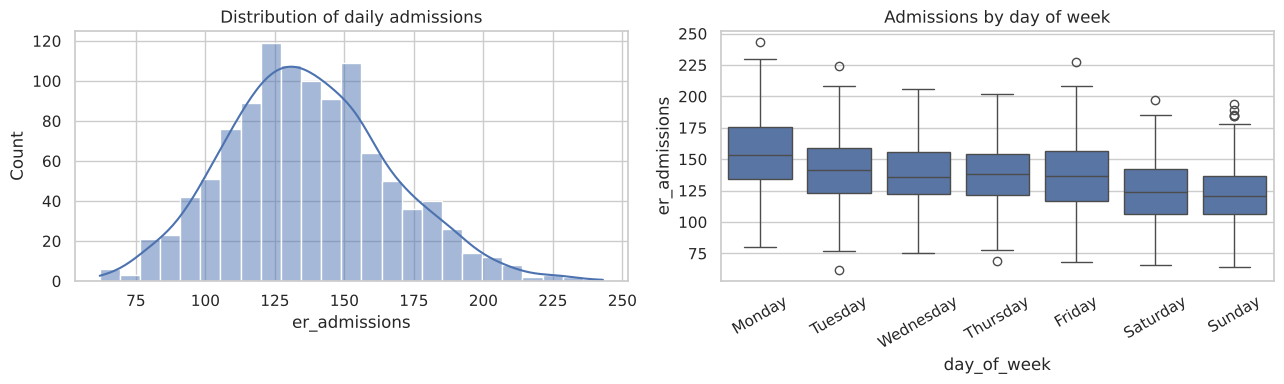

Mean = 137.1  Variance = 861.3


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13,4))
sns.histplot(df["er_admissions"], kde=True, ax=axes[0]); axes[0].set_title("Distribution of daily admissions")
sns.boxplot(data=df, x="day_of_week", y="er_admissions", ax=axes[1]); axes[1].set_title("Admissions by day of week")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
print("Mean =", round(df.er_admissions.mean(),1), " Variance =", round(df.er_admissions.var(),1))

**Observations:**
- Admissions are **counts** (whole numbers ≥ 0) and slightly right-skewed.
- **Variance ≫ mean** → the data is *over-dispersed*. A plain Poisson model assumes variance = mean, so a **Negative Binomial** model is the better count model.
- Mondays are busiest; weekends quietest (people postpone non-urgent visits).

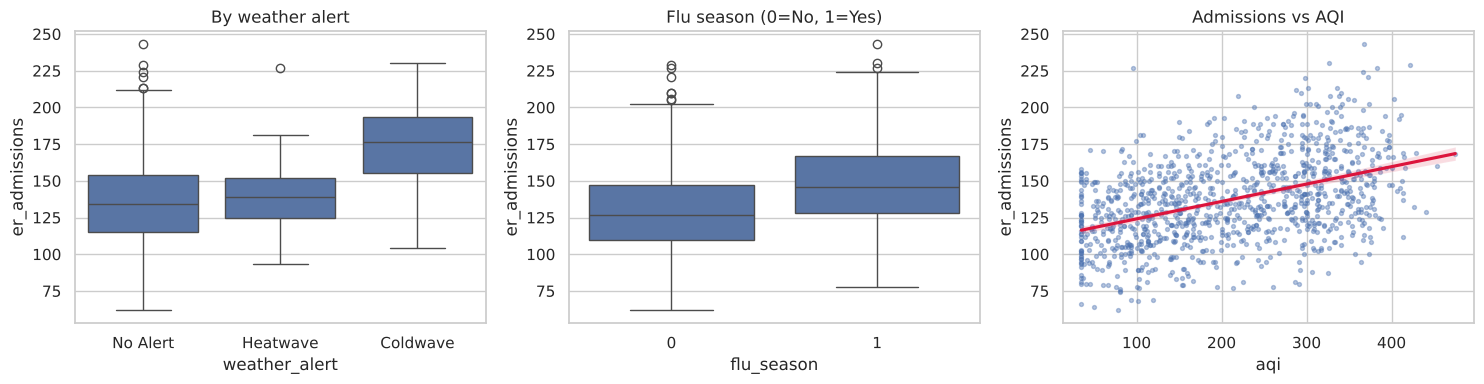

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
sns.boxplot(data=df, x="weather_alert", y="er_admissions", ax=axes[0]); axes[0].set_title("By weather alert")
sns.boxplot(data=df, x="flu_season", y="er_admissions", ax=axes[1]); axes[1].set_title("Flu season (0=No, 1=Yes)")
sns.regplot(data=df, x="aqi", y="er_admissions", scatter_kws={"s":8,"alpha":0.4}, line_kws={"color":"crimson"}, ax=axes[2]); axes[2].set_title("Admissions vs AQI")
plt.tight_layout(); plt.show()

In [9]:
df.groupby("weather_alert", observed=True)["er_admissions"].agg(["count","mean"]).round(1)

,count,mean
weather_alert,,
No Alert,981,135.2
Heatwave,69,139.9
Coldwave,46,173.0


**Observation:** Raw averages *understate* the heatwave effect. Heatwaves happen in May–June, when air is cleaner and it is not flu season — those factors pull admissions down and hide the heat effect.
This is **confounding**, and it is exactly why we need a *multiple* regression that measures each factor while holding the others constant.

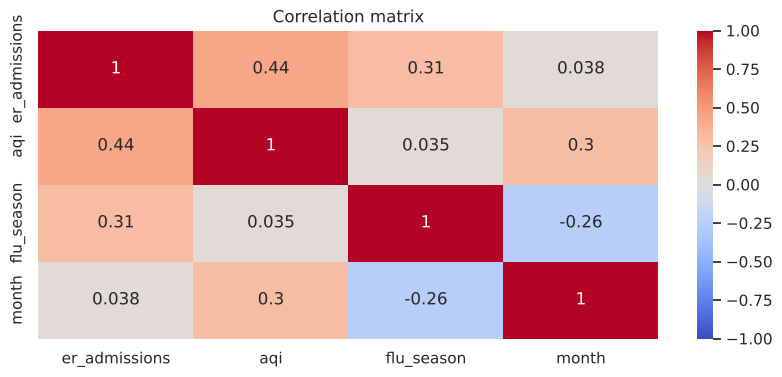

In [10]:
df["month"] = df["date"].dt.month
corr = df[["er_admissions","aqi","flu_season","month"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1); plt.title("Correlation matrix"); plt.show()

## 4. Train / test split (time-based)
For forecasting we must never train on the future. We train on **2023–2024** and test on **2025** (data the model has never seen), simulating real use.
A `trend` column (days since start) captures slow population growth.

In [11]:
df["trend"] = (df["date"] - df["date"].min()).dt.days / 365   # in years
train = df[df["date"].dt.year <= 2024].copy()
test  = df[df["date"].dt.year == 2025].copy()
print("Train:", train.shape, " Test:", test.shape)

Train: (731, 8)  Test: (365, 8)


## 5. Model 1 — Multiple Linear Regression (baseline)
$Y = \beta_0 + \beta_1 X_1 + \dots + \beta_k X_k + \varepsilon$
Categorical features are **one-hot encoded** automatically by the formula (`C(...)`), with *No Alert* and *Monday* as reference categories.

In [12]:
formula = "er_admissions ~ C(weather_alert) + C(day_of_week) + aqi + flu_season + trend"
lin = smf.ols(formula, data=train).fit()
print(lin.summary())

                            OLS Regression Results                            
Dep. Variable:          er_admissions   R-squared:                       0.500
Model:                            OLS   Adj. R-squared:                  0.492
Method:                 Least Squares   F-statistic:                     65.29
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          2.05e-100
Time:                        23:41:56   Log-Likelihood:                -3255.0
No. Observations:                 731   AIC:                             6534.
Df Residuals:                     719   BIC:                             6589.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

## 6. Model 2 — Negative Binomial Regression (main model)
Because Y is a count and over-dispersed, we model the **log** of expected admissions:
$\log(\mu) = \beta_0 + \beta_1 X_1 + \dots$  →  $\mu = e^{\beta_0} \cdot e^{\beta_1 X_1} \cdots$
So each factor **multiplies** the patient count: $e^{\beta}-1$ is the % surge. Variance $= \mu + \alpha\mu^2$, where α (alpha) measures extra randomness.

In [13]:
# Start the optimiser from a Poisson fit (+ small alpha) so it converges reliably
pois = smf.poisson(formula, data=train).fit(method="bfgs", disp=0, maxiter=2000)
nb_model = smf.negativebinomial(formula, data=train).fit(
    start_params=np.append(pois.params.values, 0.05), method="bfgs", maxiter=2000, disp=0)
print(nb_model.summary())
alpha = nb_model.params["alpha"]
print("\nConverged:", nb_model.mle_retvals["converged"], " | Dispersion alpha =", round(alpha, 4))

                     NegativeBinomial Regression Results                      
Dep. Variable:          er_admissions   No. Observations:                  731
Model:               NegativeBinomial   Df Residuals:                      719
Method:                           MLE   Df Model:                           11
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                 0.07206
Time:                        23:41:56   Log-Likelihood:                -3248.3
converged:                       True   LL-Null:                       -3500.5
Covariance Type:            nonrobust   LLR p-value:                3.543e-101
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept                        4.6815      0.023    204.995      0.000       4.637       4.726
C(weather_alert)[T.Heatwave]     0.2372      0.026      9.047      0.000     

**Check:** Compare with a Poisson model using AIC (lower = better fit after penalising complexity).

In [14]:
print("Poisson AIC          :", round(pois.aic, 1))
print("Negative Binomial AIC:", round(nb_model.aic, 1))

Poisson AIC          : 7272.2
Negative Binomial AIC: 6522.5


## 7. Model 3 — Random Forest Regressor
An ensemble of decision trees; it can learn non-linear patterns and interactions without us specifying them. Needs explicit one-hot encoding.

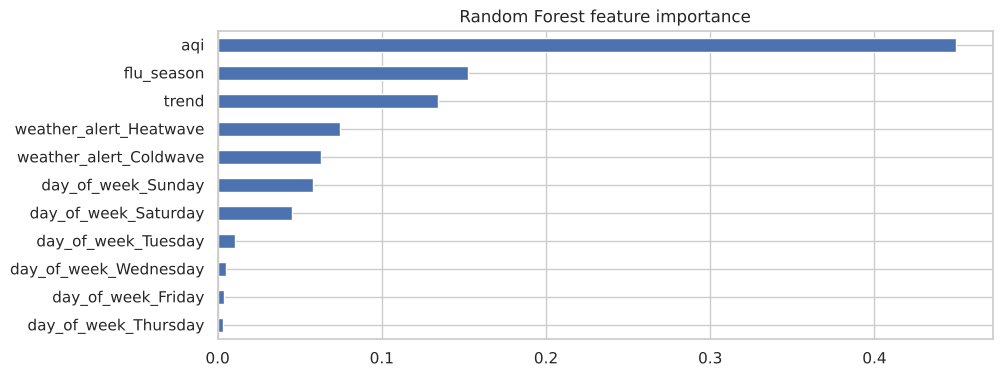

In [15]:
def make_X(d):
    X = pd.get_dummies(d[["weather_alert","day_of_week"]], drop_first=True).astype(int)
    X[["aqi","flu_season","trend"]] = d[["aqi","flu_season","trend"]]
    return X
X_train, X_test = make_X(train), make_X(test)
rf = RandomForestRegressor(n_estimators=400, max_depth=8, min_samples_leaf=5, random_state=42)
rf.fit(X_train, train["er_admissions"])
pd.Series(rf.feature_importances_, index=X_train.columns).sort_values().plot.barh(title="Random Forest feature importance")
plt.show()

## 8. Evaluation on 2025 (unseen data)

In [16]:
test["pred_linear"] = lin.predict(test)
test["pred_nb"]     = nb_model.predict(test, which="mean")
test["pred_rf"]     = rf.predict(X_test)

def scores(y, p):
    return {"MAE": mean_absolute_error(y, p),
            "RMSE": np.sqrt(mean_squared_error(y, p)),
            "R2": r2_score(y, p),
            "MAPE %": 100 * mean_absolute_percentage_error(y, p)}

results = pd.DataFrame({
    "Linear Regression": scores(test.er_admissions, test.pred_linear),
    "Negative Binomial": scores(test.er_admissions, test.pred_nb),
    "Random Forest":     scores(test.er_admissions, test.pred_rf),
}).T.round(3)
results

,MAE,RMSE,R2,MAPE %
Linear Regression,16.891,20.843,0.457,12.257
Negative Binomial,16.826,20.771,0.461,12.268
Random Forest,18.393,23.000,0.339,12.990


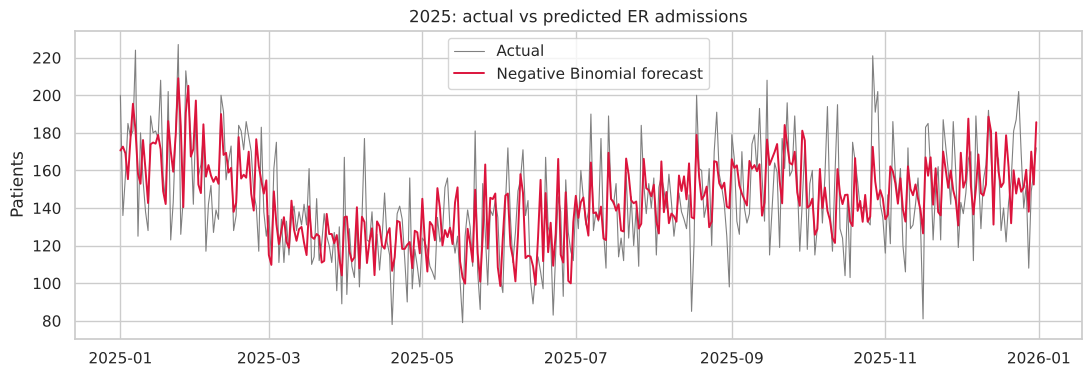

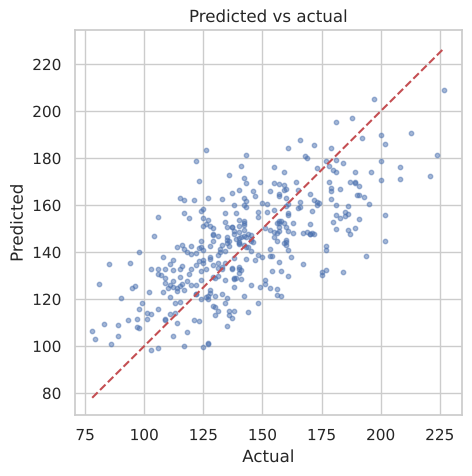

In [17]:
fig, ax = plt.subplots(figsize=(13,4))
ax.plot(test["date"], test["er_admissions"], color="grey", lw=0.8, label="Actual")
ax.plot(test["date"], test["pred_nb"], color="crimson", lw=1.4, label="Negative Binomial forecast")
ax.set_title("2025: actual vs predicted ER admissions"); ax.set_ylabel("Patients"); ax.legend(); plt.show()

fig, ax = plt.subplots(figsize=(5,5))
ax.scatter(test.er_admissions, test.pred_nb, s=10, alpha=0.5)
lims = [test.er_admissions.min(), test.er_admissions.max()]
ax.plot(lims, lims, "r--"); ax.set_xlabel("Actual"); ax.set_ylabel("Predicted"); ax.set_title("Predicted vs actual"); plt.show()

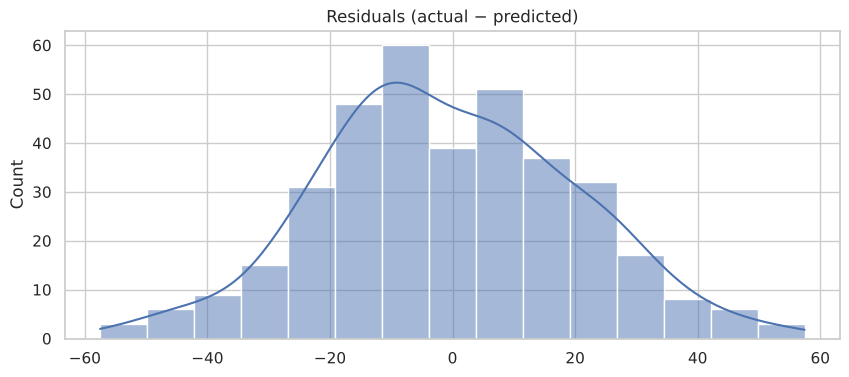

In [18]:
residuals = test.er_admissions - test.pred_nb
sns.histplot(residuals, kde=True); plt.title("Residuals (actual − predicted)"); plt.show()

## 9. Interpretation — how much surge does each factor cause?
For the Negative Binomial model, % change = $(e^{\beta} - 1) \times 100$, holding all other factors constant.

In [19]:
p = nb_model.params.drop(["Intercept","alpha","trend"])
ci = nb_model.conf_int().loc[p.index]
effects = pd.DataFrame({
    "% change in admissions": (np.exp(p) - 1) * 100,
    "95% CI low":  (np.exp(ci[0]) - 1) * 100,
    "95% CI high": (np.exp(ci[1]) - 1) * 100,
    "p-value": nb_model.pvalues.loc[p.index],
}).round(2)
effects.index = effects.index.str.replace("C(weather_alert)[T.", "Weather: ", regex=False) \
                             .str.replace("C(day_of_week)[T.", "Day: ", regex=False).str.replace("]", "", regex=False)
effects.loc["aqi (per +100 points)"] = [ (np.exp(100*nb_model.params['aqi'])-1)*100,
                                         (np.exp(100*nb_model.conf_int().loc['aqi',0])-1)*100,
                                         (np.exp(100*nb_model.conf_int().loc['aqi',1])-1)*100,
                                         nb_model.pvalues['aqi']]
effects = effects.drop("aqi").round(2)
effects

,% change in admissions,95% CI low,95% CI high,p-value
Weather: Heatwave,26.77,20.42,33.46,0.0
Weather: Coldwave,17.05,10.87,23.58,0.0
Day: Tuesday,-7.15,-10.94,-3.20,0.0
Day: Wednesday,-10.48,-14.14,-6.66,0.0
Day: Thursday,-11.14,-14.78,-7.35,0.0
Day: Friday,-10.25,-13.94,-6.40,0.0
Day: Saturday,-18.97,-22.31,-15.47,0.0
Day: Sunday,-20.91,-24.18,-17.50,0.0
flu_season,18.20,15.44,21.04,0.0
aqi (per +100 points),9.56,8.31,10.82,0.0


## 10. Staffing decision tool
A mean forecast is not enough: if we staff for the *average*, we are short-staffed on half the days.
We therefore staff for the **90th percentile** of the predicted Negative Binomial distribution (enough staff on 9 out of 10 such days).

*Staffing ratios below are planning assumptions for illustration — a hospital would substitute its own norms.*

In [20]:
PATIENTS_PER_DOCTOR = 20   # per day (assumption)
PATIENTS_PER_NURSE  = 8    # per day (assumption)
LAST_TREND = df["trend"].max()

def forecast_staffing(day, weather="No Alert", aqi=150, flu=0, service_level=0.90):
    row = pd.DataFrame({"day_of_week": pd.Categorical([day], categories=DAY_ORDER),
                        "weather_alert": pd.Categorical([weather], categories=["No Alert","Heatwave","Coldwave"]),
                        "aqi": [aqi], "flu_season": [flu], "trend": [LAST_TREND]})
    mu = float(nb_model.predict(row, which="mean").iloc[0])
    size = 1 / alpha
    upper = nbinom.ppf(service_level, size, size / (size + mu))
    return {"Expected patients": round(mu), f"Plan for ({int(service_level*100)}th pct)": int(upper),
            "Doctors": int(np.ceil(upper / PATIENTS_PER_DOCTOR)), "Nurses": int(np.ceil(upper / PATIENTS_PER_NURSE))}

scenarios = {
    "Normal Thursday, clean air":          dict(day="Thursday", aqi=90),
    "Monday, moderate air":                dict(day="Monday", aqi=180),
    "Heatwave Monday":                     dict(day="Monday", weather="Heatwave", aqi=180),
    "Severe smog (AQI 450) + flu, Monday": dict(day="Monday", aqi=450, flu=1),
    "Worst case: coldwave + AQI 450 + flu, Monday": dict(day="Monday", weather="Coldwave", aqi=450, flu=1),
}
plan = pd.DataFrame({k: forecast_staffing(**v) for k, v in scenarios.items()}).T
base = plan.iloc[0]["Expected patients"]
plan["Surge vs normal day"] = ((plan["Expected patients"] / base - 1) * 100).round(0).astype(int).astype(str) + "%"
plan

,Expected patients,Plan for (90th pct),Doctors,Nurses,Surge vs normal day
"Normal Thursday, clean air",120,144,8,18,0%
"Monday, moderate air",146,175,9,22,22%
Heatwave Monday,185,221,12,28,54%
"Severe smog (AQI 450) + flu, Monday",221,263,14,33,84%
"Worst case: coldwave + AQI 450 + flu, Monday",258,307,16,39,115%


## 11. Conclusion
- **Negative Binomial regression** is the recommended model: it suits count data, handles over-dispersion, gives easy-to-explain % effects, and provides prediction intervals for staffing. Random Forest achieves similar accuracy but is harder to explain to administrators.
- Strongest drivers of ER surges: **cold waves, heatwaves, flu season, Mondays, and poor air quality** (each +100 AQI adds a measurable % of patients).
- Combined bad conditions (cold wave + severe smog + flu on a Monday) can push demand far above a normal day — the staffing tool turns this into concrete doctor and nurse numbers.

### Limitations & future work
- Data is synthetic; validate on real hospital records (e.g., via a hospital’s HMIS or government health data).
- Add lag features (yesterday’s admissions, AQI over the last 3 days), festival/holiday flags (Diwali firecrackers worsen AQI), and temperature as a continuous variable.
- Try time-series models (SARIMAX, Prophet) and forecast multiple days ahead using weather forecasts.